# Whole-window convolutional autoencoder + simple classifier

compresses the entire patient window (20 intervals x 11 channels = 220 values) into a single
latent vector per patient, by pooling away the time axis. A simple classifier (logistic
regression) then predicts from that one vector.


## 1. Config, loading, windowing, split & scaling


In [ ]:
import os, re, zipfile
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

SUMMARY_CSV  = "summary.csv"
ZIP_PATH     = "CSVFiles.zip"
ID_COL       = "Filename"
TIME_COL     = "datetime"
OUTCOME_PATH = "Deidentified_EPCR_ZOLL_London_Trauma_ZOLL_03_04.xlsx"
OUTCOME_ID   = "Deidentified_JSON_ZOLL_x"
OUTPUT_DIR   = "outputs"; os.makedirs(OUTPUT_DIR, exist_ok=True)

WINDOW_MIN = 10
BIN_SEC    = 30
T          = WINDOW_MIN * 60 // BIN_SEC         # 20 intervals
ANCHOR     = "Hr"

CHANNELS = ["Hr", "Spo2", "Nibp_sys", "Nibp_dia", "Nibp_mean", "Ibp_sys", "Ibp_dia", "Ibp_map", "Etco2", "Resp", "SpPI"]
MEASURES = {
    "Hr":       {"token": "hr",   "value_col": "HR_value",        "vmin": 20, "vmax": 220},
    "Spo2":     {"token": "spo2", "value_col": "Spo2_value",      "vmin": 40, "vmax": 100},
    "Nibp_sys": {"token": "nibp", "value_col": "Nibp_Sys_value",  "vmin": 50, "vmax": 250},
    "Nibp_dia": {"token": "nibp", "value_col": "Nibp_Dia_value",  "vmin": 20, "vmax": 150},
    "Nibp_mean":{"token": "nibp", "value_col": "Nibp_mean_value", "vmin": 30, "vmax": 180},
    "Ibp_sys":   {"token": "ibp", "value_col": "ibp0_Sys_value", "vmin": 50, "vmax": 250},
    "Ibp_dia":   {"token": "ibp",  "value_col": "ibp0_Dia_value", "vmin": 20, "vmax": 150},
    "Ibp_map":   {"token": "ibp",  "value_col": "ibp0_Mean_value",  "vmin": 30, "vmax": 180},
    "Etco2":    {"token": "etco2","value_col": "Etco2_value",     "vmin": 5,  "vmax": 80},
    "Resp":     {"token": "resp", "value_col": "Resp_value",      "vmin": 3,  "vmax": 60},
    "SpPI": {"token": "sppi", "value_col": "PI_value",  "vmin": 0,  "vmax": 100}
}
C = len(CHANNELS)
LATENT_SWEEP = [6,7,8,9,10,11,12]

df = pd.read_csv(SUMMARY_CSV); df.columns = [c.strip() for c in df.columns]
zf = zipfile.ZipFile(ZIP_PATH); names = set(zf.namelist())
print("recordings in summary:", len(df))

recordings in summary: 606


In [ ]:
# find the right per-channel csv in the zip for a given recording ID
def detail_name(fn, token):
    fnl = str(fn).lower()
    for n in names:
        b = n.lower()
        if fnl in b and b.endswith(".csv") and re.search(rf"(^|[_/]){token}([_.])", b):
            return n
    return None

# load one channel's raw csv for one patient
def load_channel(fn, cfg):
    """valid-and-nonzero, in-range, de-duplicated readings: DataFrame[t, val]."""
    name = detail_name(fn, cfg["token"])
    if name is None:
        return None
    with zf.open(name) as f:
        d = pd.read_csv(f)
    d.columns = [c.strip() for c in d.columns]
    vcol = cfg["value_col"]

    vpos = d.columns.get_loc(vcol)
    if vpos == 0 or TIME_COL not in d.columns:
        return None
    scol = d.columns[vpos - 1]     # status column = one to the left of value column

    # parse the time column into actual datetime object
    t   = pd.to_datetime(d[TIME_COL], errors="coerce")
    val = pd.to_numeric(d[vcol], errors="coerce") / cfg.get("scale", 1)
    valid = d[scol].astype(str).str.strip().str.lower().eq("valid")

    # choose valid, in range, non-zero, deduplicated readings
    o = pd.DataFrame({"t": t, "val": val, "valid": valid}).dropna(subset=["t"])
    good = o["valid"] & (o["val"] != 0) & o["val"].between(cfg["vmin"], cfg["vmax"])
    return o[good].drop_duplicates(subset=["t", "val"]).sort_values("t")

# load hr series to anchor the time period
def build_window(fn):
    hr = load_channel(fn, MEASURES[ANCHOR])
    if hr is None or len(hr) == 0:
        return None
    t_end   = hr["t"].max()
    t_start = t_end - pd.Timedelta(seconds=WINDOW_MIN * 60)
    if hr["t"].min() > t_start:                 # require a full 10-min HR span
        return None
    # 2 output arrays for each patient ( 20 internals x 11 channels)
    data = np.zeros((T, C), dtype="float32")
    mask = np.zeros((T, C), dtype="float32")

    # loops over the 11 channels
    for ci, ch in enumerate(CHANNELS):
        s = hr if ch == ANCHOR else load_channel(fn, MEASURES[ch])
        if s is None or len(s) == 0:
            continue                             # channel absent -> stays masked

        # how many seconds before t_end each readings occurred
        sb = (t_end - s["t"]).dt.total_seconds().to_numpy()
        inwin = (sb >= 0) & (sb < WINDOW_MIN * 60)
        sb, vv = sb[inwin], s["val"].to_numpy()[inwin]
        if len(vv) == 0:
            continue
        # create a bin index
        b = (T - 1 - (sb // BIN_SEC)).astype(int)

        # aggreagate to the mean, add mask
        for bi in np.unique(b):
            data[bi, ci] = vv[b == bi].mean()
            mask[bi, ci] = 1.0
    return data, mask

In [ ]:
# create 2D arrays Xs and Ms of shape (20,11), where Xs stores the measures and Ms the mask
Xs, Ms, ids = [], [], []
for fn in df[ID_COL]:
    r = build_window(fn)
    if r is not None:
        Xs.append(r[0]); Ms.append(r[1]); ids.append(fn)

# create a 3D tensor of shape (n_patients, 20, 11), where a 20 x 11 table is stored for every patient
X = np.stack(Xs); M = np.stack(Ms); ids = np.array(ids)
print(f"kept {len(ids)} of {len(df)} patients | X shape {X.shape} (patients, intervals, channels)")

# compute a fraction of all cells that have an actual reading (mask = 1)
print("per-channel % intervals observed:")
for ci, ch in enumerate(CHANNELS):
    print(f"  {ch:10s}: {M[:,:,ci].mean()*100:5.1f}%")

kept 603 of 606 patients | X shape (603, 20, 11) (patients, intervals, channels)
per-channel % intervals observed:
  Hr        :  92.7%
  Spo2      :  72.7%
  Nibp_sys  :  40.0%
  Nibp_dia  :  39.9%
  Nibp_mean :  39.8%
  Ibp_sys   :  19.2%
  Ibp_dia   :  19.5%
  Ibp_map   :  19.5%
  Etco2     :  52.8%
  Resp      :  67.6%
  SpPI      :  40.4%


In [ ]:
idx = np.arange(len(ids))
tr, tmp = train_test_split(idx, test_size=0.30, random_state=42)
va, te  = train_test_split(tmp, test_size=0.50, random_state=42)

# for each channel gather only observed (mask=1) training values and compute their 95 percentile to use it as per channel scale factor
scale = np.ones(C)
percentile = 95
for ci in range(C):
    vals = X[tr][:, :, ci][M[tr][:, :, ci] > 0]
    if len(vals):
        scale[ci] = np.percentile(vals, percentile) + 1e-6

Xn = (X / scale) * M   # missing values remain exactly zero

print("train/val/test patients:", len(tr), len(va), len(te))

train/val/test patients: 422 90 91


## 2. Whole-window convolutional autoencoder

The encoder runs 1D convolutions along time, then an adaptive average pool collapses the 20
intervals into one vector, which a linear layer maps to the patient latent (compression:
220 -> LATENT). The decoder expands the latent back to the full 20x11 window. Trained with the
same masked reconstruction loss (missing channels excluded).

whole-window latent 5: masked val MSE 0.02968 +/- 0.00212
whole-window latent 6: masked val MSE 0.03317 +/- 0.00357
whole-window latent 7: masked val MSE 0.03038 +/- 0.00280
whole-window latent 8: masked val MSE 0.02853 +/- 0.00201
whole-window latent 9: masked val MSE 0.02838 +/- 0.00170
whole-window latent 10: masked val MSE 0.02978 +/- 0.00242
whole-window latent 11: masked val MSE 0.02960 +/- 0.00149
whole-window latent 12: masked val MSE 0.02909 +/- 0.00260
whole-window latent 13: masked val MSE 0.02790 +/- 0.00244
whole-window latent 14: masked val MSE 0.03182 +/- 0.00455
whole-window latent 15: masked val MSE 0.02754 +/- 0.00269
whole-window latent 16: masked val MSE 0.02808 +/- 0.00324
whole-window latent 17: masked val MSE 0.02784 +/- 0.00147
whole-window latent 18: masked val MSE 0.02731 +/- 0.00244
whole-window latent 19: masked val MSE 0.02787 +/- 0.00244


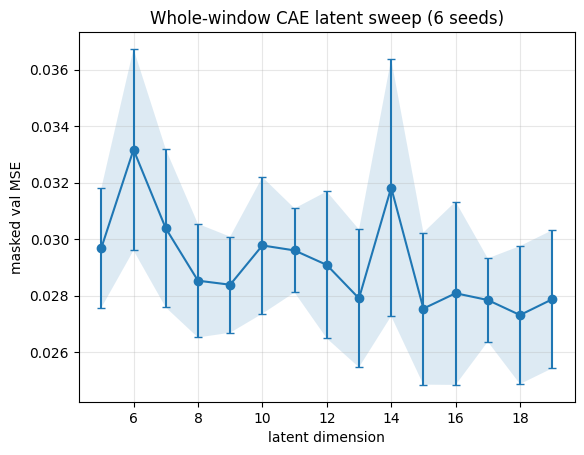

In [ ]:
def to_t(a): return torch.tensor(a, dtype=torch.float32)


def masked_mse(recon, x, m): return ((recon - x) ** 2 * m).sum() / (m.sum() + 1e-8)

class WholeWindowCAE(nn.Module):
    def __init__(self, C, latent, T):
        super().__init__()
        self.T = T
        # encoder: 1D convs along time. Input shape (batch, C=channels, T=number of time steps)
        self.enc_conv = nn.Sequential(
            nn.Conv1d(C, 16, kernel_size=3, padding=1), nn.ReLU(), # local time patterns (603 patients, 16 feature maps, 20 time intervals)
            nn.Conv1d(16, 64, kernel_size=3, padding=1), nn.ReLU(),  # -> latent per time-step (603 patients, 11 latent features, 10 time intervals)
        )
        self.pool = nn.AdaptiveAvgPool1d(1)          # averages each feature map, collapse the 20 intervals -> 1
        self.enc_fc = nn.Linear(64, latent)          # 220 (via conv+pool) -> latent per patient
        # decoder: latent -> whole window (20 x C)
        self.dec_fc = nn.Linear(latent, 16 * T)
        self.dec_conv = nn.Sequential(
            nn.Conv1d(16, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv1d(16, C, kernel_size=3, padding=1),
        )
    def encode(self, x):
        x = x.transpose(1, 2)                 # (B, T, C) -> (B, C, T)
        h = self.enc_conv(x)                  # (B, 16, T)
        h = self.pool(h).squeeze(-1)          # (B, 16) — time pooled away
        return self.enc_fc(h)                 # (B, latent) — one vector per patient
    def forward(self, x):
        z = self.encode(x)                    # (B, latent)
        h = self.dec_fc(z).view(-1, 16, self.T)   # (B, 16, T)
        recon = self.dec_conv(h).transpose(1, 2)  # (B, T, C)
        return recon, z

def train_ww_cae(latent, epochs=120, lr=1e-3, batch=64, seed=42):
    torch.manual_seed(seed)
    Xtr, Mtr = to_t(Xn[tr]), to_t(M[tr])
    Xva, Mva = to_t(Xn[va]), to_t(M[va])
    model = WholeWindowCAE(C, latent, T); opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for b in torch.randperm(len(Xtr)).split(batch):
            opt.zero_grad()
            recon, _ = model(Xtr[b]); loss = masked_mse(recon, Xtr[b], Mtr[b])
            loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        vl = masked_mse(model(Xva)[0], Xva, Mva).item()
    return model, vl

SWEEP_SEEDS = range(6)

ww_cae = {}
for latent in range(5, 20):
    vals, models = [], []
    for s in SWEEP_SEEDS:
        model, vl = train_ww_cae(latent, seed=s)
        vals.append(vl); models.append(model)
    vals = np.array(vals)
    # keep the median-performing seed's model, not the luckiest one
    keep = int(np.argsort(vals)[len(vals) // 2])
    ww_cae[latent] = {"model": models[keep], "val": vals.mean(),
                      "std": vals.std(), "all": vals}
    print(f"whole-window latent {latent}: masked val MSE "
          f"{vals.mean():.5f} +/- {vals.std():.5f}")

ks   = list(ww_cae)
mean = np.array([ww_cae[k]["val"] for k in ks])
sd   = np.array([ww_cae[k]["std"] for k in ks])

plt.errorbar(ks, mean, yerr=sd, fmt="o-", capsize=3)
plt.fill_between(ks, mean - sd, mean + sd, alpha=.15)
plt.xlabel("latent dimension"); plt.ylabel("masked val MSE")
plt.title(f"Whole-window CAE latent sweep ({len(SWEEP_SEEDS)} seeds)")
plt.grid(alpha=.3); plt.show()

In [ ]:
WW_LATENT = 9
ww_encoder = ww_cae[WW_LATENT]["model"]; ww_encoder.eval()

with torch.no_grad():
    Zpat = ww_encoder.encode(to_t(Xn)).numpy()      # (N, 9) — one vector per patient
print("patient latent matrix:", Zpat.shape)

# labels
outc = pd.read_excel(OUTCOME_PATH); outc.columns = [c.strip() for c in outc.columns]
lab  = outc.set_index(OUTCOME_ID)
def get_label(column):
    return pd.to_numeric(pd.Series(ids).map(lab[column]), errors="coerce").to_numpy()
print("label join match: %.1f%%" % (pd.Series(ids).isin(lab.index).mean() * 100))

patient latent matrix: (603, 9)
label join match: 100.0%


## 3. CAE + Logistic Regression on the patient latent

A logistic-regression head predicts each outcome from the single
patient latent, reported as multi-seed test AUROC.

In [ ]:

def make_target(task):
    if task == "mortality":
        return pd.to_numeric(pd.Series(get_label("Outcome Alive 0/Dead 1")), errors="coerce").to_numpy()
    if task == "transfusion":
        raw = pd.to_numeric(pd.Series(get_label("24hr Prehospital + Hospital Blood Transfusion")),
                            errors="coerce").to_numpy()
        return np.where(np.isnan(raw), np.nan, (raw >= 10).astype(float))
    if task == "lactate":                          # high (>=4 mmol/L) vs normal
        raw = pd.to_numeric(pd.Series(get_label("First lactate (hospital arrival)")), errors="coerce").to_numpy()
        return np.where(np.isnan(raw), np.nan, (raw >= 4).astype(float))
    raise ValueError(task)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# automatic fine-tuning of logistic regression via cross-validated grid search
def eval_ww_tuned(task, latent, seed):
    model, _ = train_ww_cae(latent, seed=seed)
    # switch the autoencoder to evaluation mode
    model.eval()
    # get the patient's latent matrix
    with torch.no_grad():
        Z = model.encode(to_t(Xn)).numpy()
    y = make_target(task)
    # filter a set of patient indices to those with a non-missing label
    keep = lambda ss: np.array([i for i in ss if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)

    pipe = Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=1000))])
    # hyperprameter search space
    grid = {
        "lr__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "lr__penalty": ["l2"],
        "lr__solver": ["lbfgs"],
    }
    # cross-validate on the TRAINING data only, scoring by AUROC
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=5, n_jobs=-1)
    search.fit(Z[trL], y[trL])

    p = search.predict_proba(Z[teL])[:, 1]
    return roc_auc_score(y[teL], p), search.best_params_["lr__C"]

# average AUROC per 6 seeds
SEEDS = range(6)
for task in ["mortality", "transfusion", "lactate"]:
    results = [eval_ww_tuned(task, WW_LATENT, s) for s in SEEDS]
    aucs = np.array([r[0] for r in results])
    best_Cs = [r[1] for r in results]
    print(f"{task:12s}: test AUROC {aucs.mean():.3f} ± {aucs.std():.3f}  "
          f"(chosen C per seed: {best_Cs})")

mortality   : test AUROC 0.736 ± 0.086  (chosen C per seed: [0.3, 3, 10, 1, 0.3, 10])
transfusion : test AUROC 0.730 ± 0.039  (chosen C per seed: [10, 1, 10, 10, 1, 10])
lactate     : test AUROC 0.627 ± 0.033  (chosen C per seed: [0.3, 0.3, 0.1, 0.1, 1, 1])


### a) calibration

mortality: 390 train / 84 test patients, 15 positives in test
Brier (model):    0.131 +/- 0.010
Brier (baseline): 0.147  (base rate 0.18)

mean_predicted_risk  actual_death_rate
     0.04                 0.00
     0.09                 0.06
     0.15                 0.25
     0.20                 0.18
     0.29                 0.41


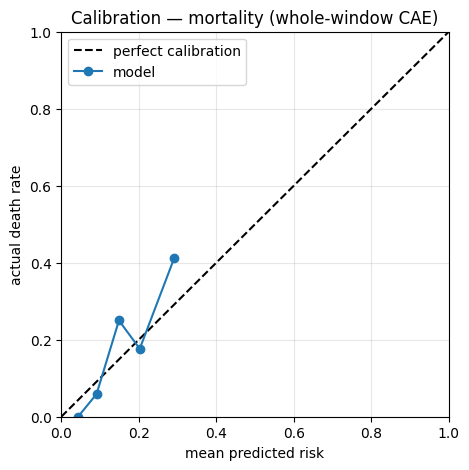

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

task = "mortality"
y = make_target(task)
keep = lambda ss: np.array([i for i in ss if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)
y_true = y[teL]
print(f"{task}: {len(trL)} train / {len(teL)} test patients, "
      f"{int(y_true.sum())} positives in test")

ps = []
for s in range(6):
    model, _ = train_ww_cae(WW_LATENT, seed=s); model.eval()
    with torch.no_grad():
        Z = model.encode(to_t(Xn)).numpy()
    search = GridSearchCV(Pipeline([("sc", StandardScaler()),
                                    ("lr", LogisticRegression(max_iter=1000))]),
                          {"lr__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                          scoring="roc_auc", cv=5, n_jobs=-1).fit(Z[trL], y[trL])
    ps.append(search.predict_proba(Z[teL])[:, 1])

assert all(len(p) == len(y_true) for p in ps)
briers = np.array([brier_score_loss(y_true, p) for p in ps])
base_rate = y_true.mean()
brier_baseline = brier_score_loss(y_true, np.full(len(y_true), base_rate))
print(f"Brier (model):    {briers.mean():.3f} +/- {briers.std():.3f}")
print(f"Brier (baseline): {brier_baseline:.3f}  (base rate {base_rate:.2f})\n")

p_te = np.mean(ps, axis=0)
frac_pos, mean_pred = calibration_curve(y_true, p_te, n_bins=5, strategy="quantile")
print("mean_predicted_risk  actual_death_rate")
for mp, fp in zip(mean_pred, frac_pos):
    print(f"     {mp:.2f}                 {fp:.2f}")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", label="model")
plt.xlabel("mean predicted risk"); plt.ylabel("actual death rate")
plt.title("Calibration — mortality (whole-window CAE)")
plt.legend(); plt.grid(alpha=.3); plt.xlim(0, 1); plt.ylim(0, 1); plt.show()

transfusion: 421 train / 91 test patients, 18 positives in test
Brier (model):    0.146 +/- 0.003
Brier (baseline): 0.159  (base rate 0.20)

mean_predicted_risk  actual_rate
     0.10                 0.04
     0.14                 0.09
     0.20                 0.32
     0.26                 0.35


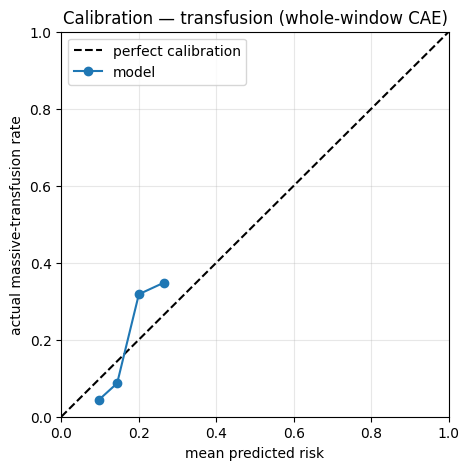

In [ ]:
task = "transfusion"
y = make_target(task)
keep = lambda ss: np.array([i for i in ss if not np.isnan(y[i])])
trL, teL = keep(tr), keep(te)
y_true = y[teL]
print(f"{task}: {len(trL)} train / {len(teL)} test patients, "
      f"{int(y_true.sum())} positives in test")

ps = []
for s in range(6):
    model, _ = train_ww_cae(WW_LATENT, seed=s); model.eval()
    with torch.no_grad():
        Z = model.encode(to_t(Xn)).numpy()
    search = GridSearchCV(Pipeline([("sc", StandardScaler()),
                                    ("lr", LogisticRegression(max_iter=1000))]),
                          {"lr__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                          scoring="roc_auc", cv=5, n_jobs=-1).fit(Z[trL], y[trL])
    ps.append(search.predict_proba(Z[teL])[:, 1])

assert all(len(p) == len(y_true) for p in ps)
briers = np.array([brier_score_loss(y_true, p) for p in ps])
base_rate = y_true.mean()
brier_baseline = brier_score_loss(y_true, np.full(len(y_true), base_rate))
print(f"Brier (model):    {briers.mean():.3f} +/- {briers.std():.3f}")
print(f"Brier (baseline): {brier_baseline:.3f}  (base rate {base_rate:.2f})\n")

p_te = np.mean(ps, axis=0)
frac_pos, mean_pred = calibration_curve(y_true, p_te, n_bins=4, strategy="quantile")
print("mean_predicted_risk  actual_rate")
for mp, fp in zip(mean_pred, frac_pos):
    print(f"     {mp:.2f}                 {fp:.2f}")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", label="model")
plt.xlabel("mean predicted risk"); plt.ylabel("actual massive-transfusion rate")
plt.title("Calibration — transfusion (whole-window CAE)")
plt.legend(); plt.grid(alpha=.3); plt.xlim(0, 1); plt.ylim(0, 1); plt.show()

## Export test probabilities for the combined ROC


In [ ]:
# export seed-averaged test probabilities for the combined ROC
# Mirrors eval_ww_tuned exactly (same encoder, same CV grid, same splits), but
# keeps the predicted probabilities instead of collapsing them to an AUROC.
# Patient ids are exported alongside so the other notebook can verify that the
# two pipelines really did select the same test patients before plotting.

EXPORT_SEEDS = range(6)
GRID = {"lr__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "lr__penalty": ["l2"], "lr__solver": ["lbfgs"]}

out = {}
for task in ["mortality", "transfusion", "lactate"]:
    y = make_target(task)
    keep = lambda ss: np.array([i for i in ss if not np.isnan(y[i])])
    trL, teL = keep(tr), keep(te)

    ps = []
    for s in EXPORT_SEEDS:
        model, _ = train_ww_cae(WW_LATENT, seed=s); model.eval()
        with torch.no_grad():
            Z = model.encode(to_t(Xn)).numpy()
        pipe = Pipeline([("sc", StandardScaler()),
                         ("lr", LogisticRegression(max_iter=1000))])
        search = GridSearchCV(pipe, GRID, scoring="roc_auc", cv=5, n_jobs=-1)
        search.fit(Z[trL], y[trL])
        ps.append(search.predict_proba(Z[teL])[:, 1])

    ps = np.array(ps)
    out[f"{task}_p"]   = ps.mean(axis=0)                 # seed-averaged
    out[f"{task}_y"]   = y[teL]
    out[f"{task}_ids"] = np.asarray(ids, dtype=str)[teL]
    aucs = np.array([roc_auc_score(y[teL], p) for p in ps])
    out[f"{task}_aucs"] = aucs
    print(f"{task:12s}: n_test {len(teL):3d} | per-seed AUROC "
          f"{aucs.mean():.3f} +/- {aucs.std():.3f}")

np.savez("ww_test_probs.npz", **out)
print("\nwrote ww_test_probs.npz -> copy it next to Mean_agg_pipeline")


mortality   : n_test  84 | per-seed AUROC 0.736 +/- 0.086
transfusion : n_test  91 | per-seed AUROC 0.730 +/- 0.039
lactate     : n_test  67 | per-seed AUROC 0.627 +/- 0.033

wrote ww_test_probs.npz -> copy it next to Mean_agg_pipeline
